# Publication-ready hidden-state similarity heatmaps

This notebook replots the complete repeat-by-repeat similarity matrices exported by `ca_analyze plot-state`. Edit only the source labels and paths in the configuration cell; internal run identifiers are never used as figure titles.

In [1]:
# >>> RUN 1/4 FOR R6 ACCURACY + COSINE: imports <<<
from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

In [6]:
def find_repo_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "iridis" / "ca-rule30" / "runs").is_dir():
            return candidate
    raise FileNotFoundError("Run this notebook from inside the rs-cot repository.")


REPO_ROOT = find_repo_root()
OUTPUT_DIR = REPO_ROOT / "dis-draft" / "dis-images" / "hidden-state-similarity"

# Replace paths or labels here when plotting other exported matrices.
PLOTS = [
    {
        "csv": Path("/tmp/run124-state-heatmap/hidden_state.csv"),
        "title": "BUT — model seed 0 ($R_4$)",
        "output_stem": "but-r4-seed-0-hidden-state-similarity",
    },
    {
        "csv": Path("/tmp/run128-state-heatmap/hidden_state.csv"),
        "title": "BUT — model seed 2 ($R_4$)",
        "output_stem": "but-r4-seed-2-hidden-state-similarity",
    },
]

COLOR_LIMITS = (0.0, 1.0)
COLOR_MAP = "viridis"
OUTPUT_DPI = 300

In [2]:
# >>> RUN 2/4 FOR R6 ACCURACY + COSINE: repository setup <<<
def find_repo_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "iridis" / "ca-rule30" / "runs").is_dir():
            return candidate
    raise FileNotFoundError("Run this notebook from inside the rs-cot repository.")


REPO_ROOT = find_repo_root()
SOURCE_DIR = (
    REPO_ROOT
    / "iridis/ca-rule30/reports/paper-rule30/r6-lstm-hidden-state"
)
OUTPUT_DIR = (
    REPO_ROOT
    / "lstm-ut-arxiv/dis-images/hidden-state-similarity/r6-lstm-ut"
)

RUNS = [
    # (width, model seed, run number, run suffix)
    (32, 0, 317, "ca_lstm_d32_r6_zero"),
    (32, 1, 318, "ca_lstm_d32_r6_zero"),
    (32, 2, 319, "ca_lstm_d32_r6_zero"),
    (32, 3, 320, "ca_lstm_d32_r6_zero"),
    (32, 4, 321, "ca_lstm_d32_r6_zero"),
    (64, 0, 34, "ca_lstm_r6_zero"),
    (64, 1, 44, "ca_lstm_r6_zero"),
    (64, 2, 54, "ca_lstm_r6_zero"),
    (64, 3, 64, "ca_lstm_r6_zero"),
    (64, 4, 74, "ca_lstm_r6_zero"),
]

PLOTS = [
    {
        "csv": SOURCE_DIR / f"run_{number}__{suffix}" / "hidden_state.csv",
        "title": f"LSTM-UT d{width} — model seed {seed} ($R_6$)",
        "output_stem": f"lstm-ut-r6-d{width}-seed-{seed}-hidden-state-similarity",
    }
    for width, seed, number, suffix in RUNS
]

COLOR_LIMITS = (0.0, 1.0)
COLOR_MAP = "viridis"
OUTPUT_DPI = 300

In [4]:
REQUIRED_COLUMNS = {
    "checkpoint_step",
    "repeat_from",
    "repeat_to",
    "metric",
    "value",
}


def load_similarity_matrix(csv_path):
    data = pd.read_csv(csv_path)
    missing = REQUIRED_COLUMNS.difference(data.columns)
    if missing:
        raise ValueError(f"{csv_path} is missing columns: {sorted(missing)}")

    metrics = data["metric"].dropna().unique()
    if len(metrics) != 1 or metrics[0] != "cosine_similarity":
        raise ValueError(f"Expected only cosine_similarity records, found {metrics.tolist()}")

    steps = data["checkpoint_step"].dropna().astype(int).unique()
    if len(steps) != 1:
        raise ValueError(f"Expected one checkpoint step, found {steps.tolist()}")

    if data.duplicated(["repeat_from", "repeat_to"]).any():
        raise ValueError("The CSV contains duplicate repeat-pair measurements.")

    matrix = (
        data.pivot(index="repeat_from", columns="repeat_to", values="value")
        .sort_index(axis=0)
        .sort_index(axis=1)
    )
    if matrix.index.tolist() != matrix.columns.tolist():
        raise ValueError("Row and column repeat indices do not match.")
    if matrix.isna().any().any():
        raise ValueError("The exported repeat-by-repeat matrix is incomplete.")
    if not np.allclose(matrix.to_numpy(), matrix.to_numpy().T, atol=1e-6):
        raise ValueError("Cosine-similarity matrix is not symmetric.")
    if matrix.to_numpy().min() < COLOR_LIMITS[0] or matrix.to_numpy().max() > COLOR_LIMITS[1]:
        raise ValueError("Matrix values fall outside COLOR_LIMITS; widen the configured scale.")

    return data, matrix, int(steps[0])


def plot_similarity_heatmap(matrix, checkpoint_step, title, output_stem):
    repeats = matrix.index.to_numpy(dtype=int)
    size = max(6.6, min(8.8, 5.8 + len(repeats) / 18))
    fig, ax = plt.subplots(figsize=(size + 0.7, size), constrained_layout=True)

    image = ax.imshow(
        matrix.to_numpy(),
        origin="lower",
        interpolation="nearest",
        aspect="equal",
        cmap=COLOR_MAP,
        vmin=COLOR_LIMITS[0],
        vmax=COLOR_LIMITS[1],
    )

    tick_stride = max(1, math.ceil(len(repeats) / 11))
    tick_positions = list(range(0, len(repeats), tick_stride))
    if tick_positions[-1] != len(repeats) - 1:
        tick_positions.append(len(repeats) - 1)
    tick_labels = repeats[tick_positions]
    ax.set_xticks(tick_positions, tick_labels)
    ax.set_yticks(tick_positions, tick_labels)
    ax.set_xlabel(r"Repeat $s$")
    ax.set_ylabel(r"Repeat $r$")
    ax.set_title(f"{title}\nCheckpoint step {checkpoint_step:,}", pad=10)
    ax.tick_params(direction="out", length=4, width=0.8)

    colorbar = fig.colorbar(image, ax=ax, shrink=0.84, pad=0.025)
    colorbar.set_label("Cosine Similarity")

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    png_path = OUTPUT_DIR / f"{output_stem}.png"
    pdf_path = OUTPUT_DIR / f"{output_stem}.pdf"
    fig.savefig(png_path, dpi=OUTPUT_DPI, bbox_inches="tight", facecolor="white")
    fig.savefig(pdf_path, bbox_inches="tight", facecolor="white")
    plt.show()
    return png_path, pdf_path

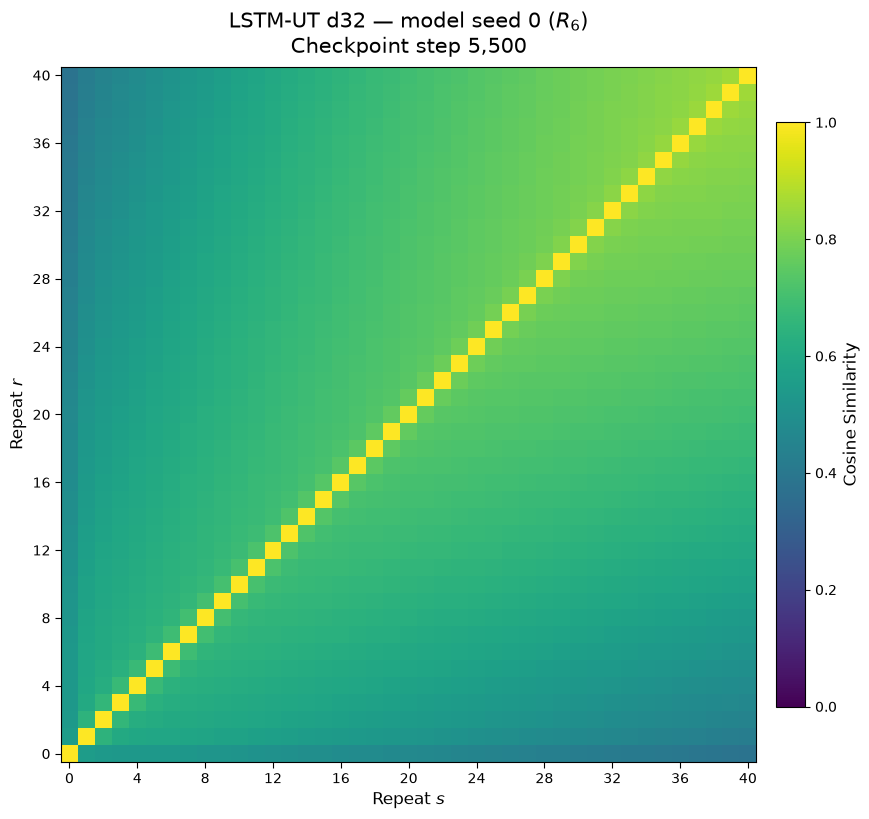

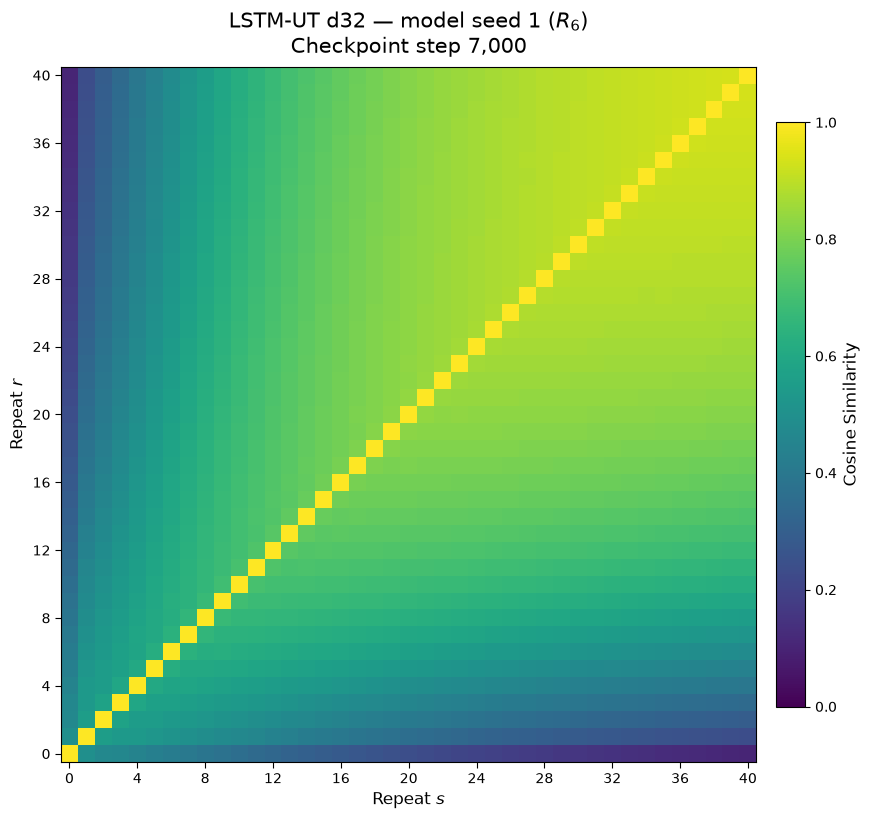

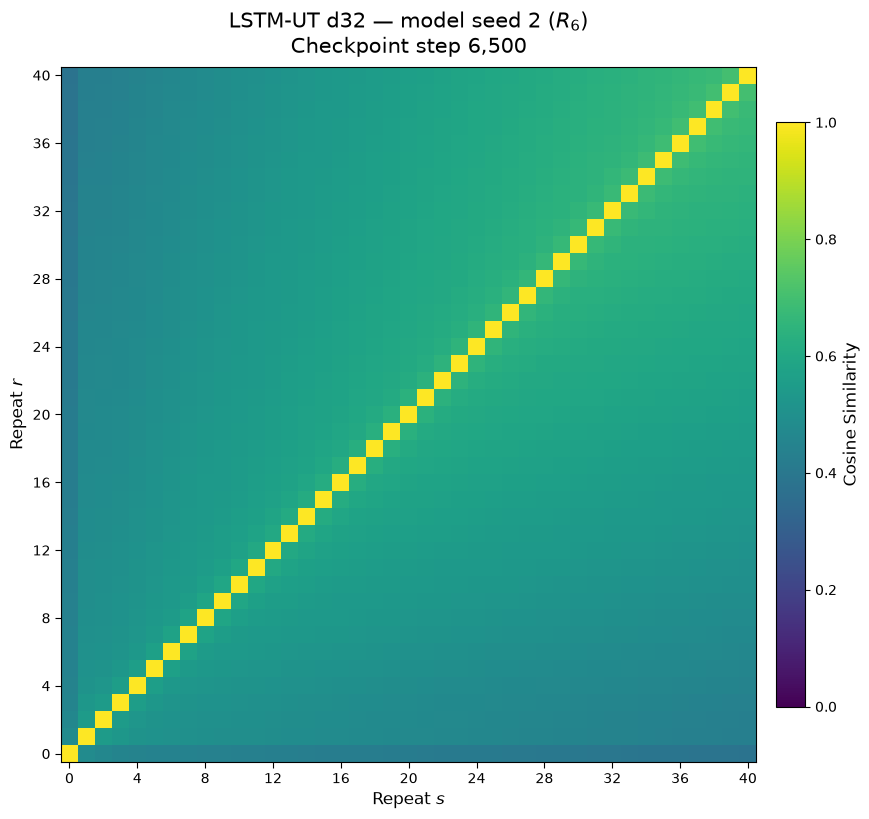

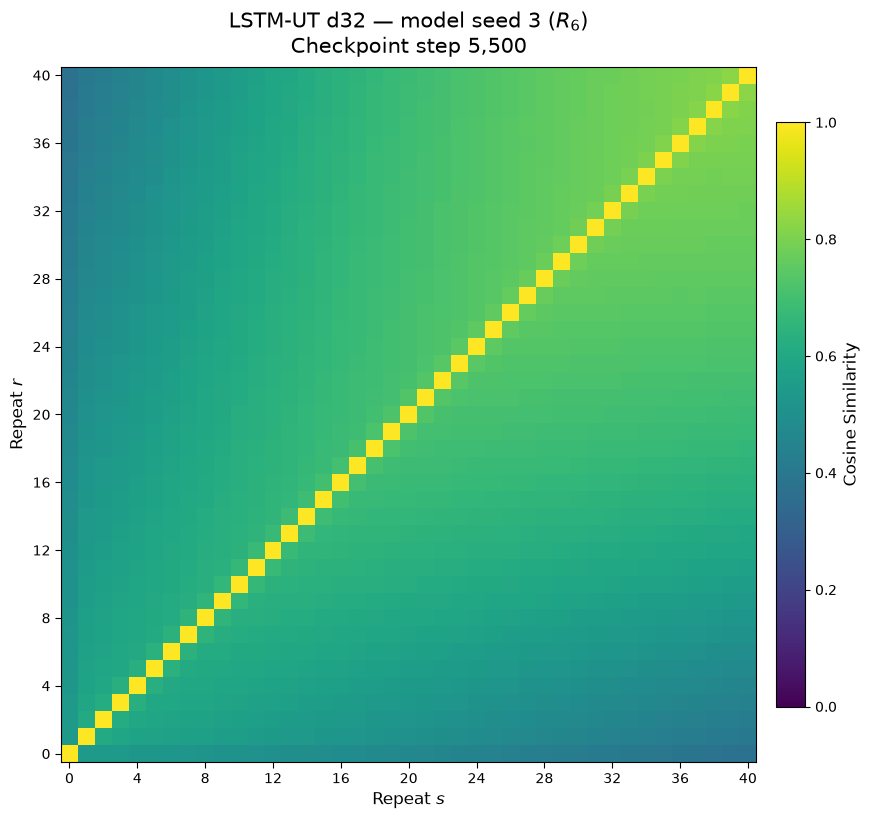

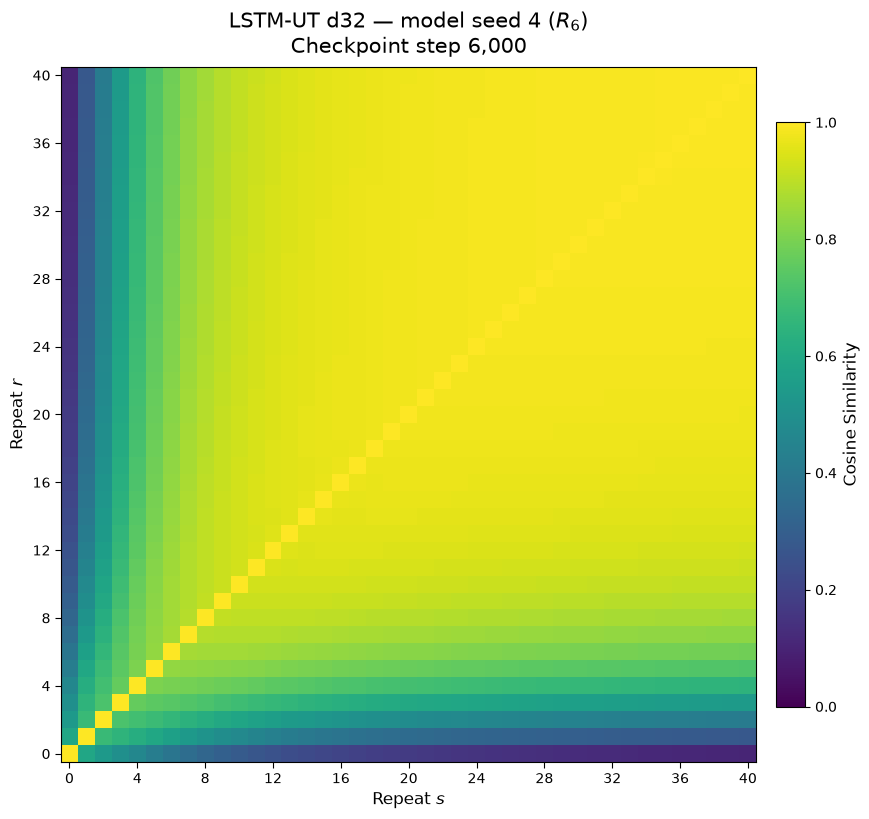

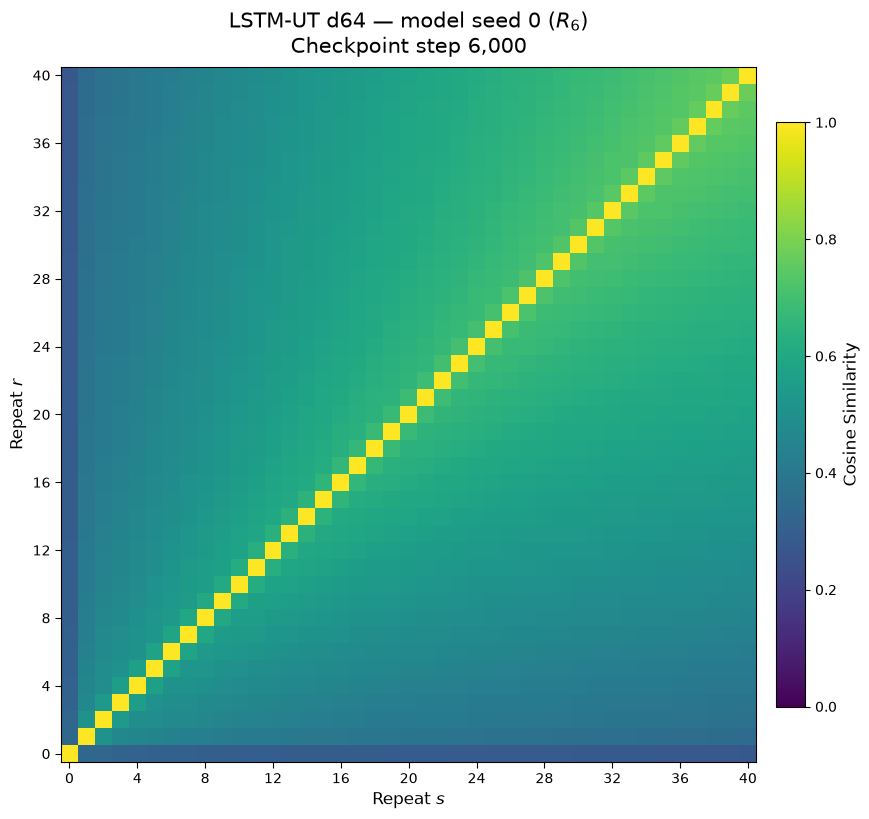

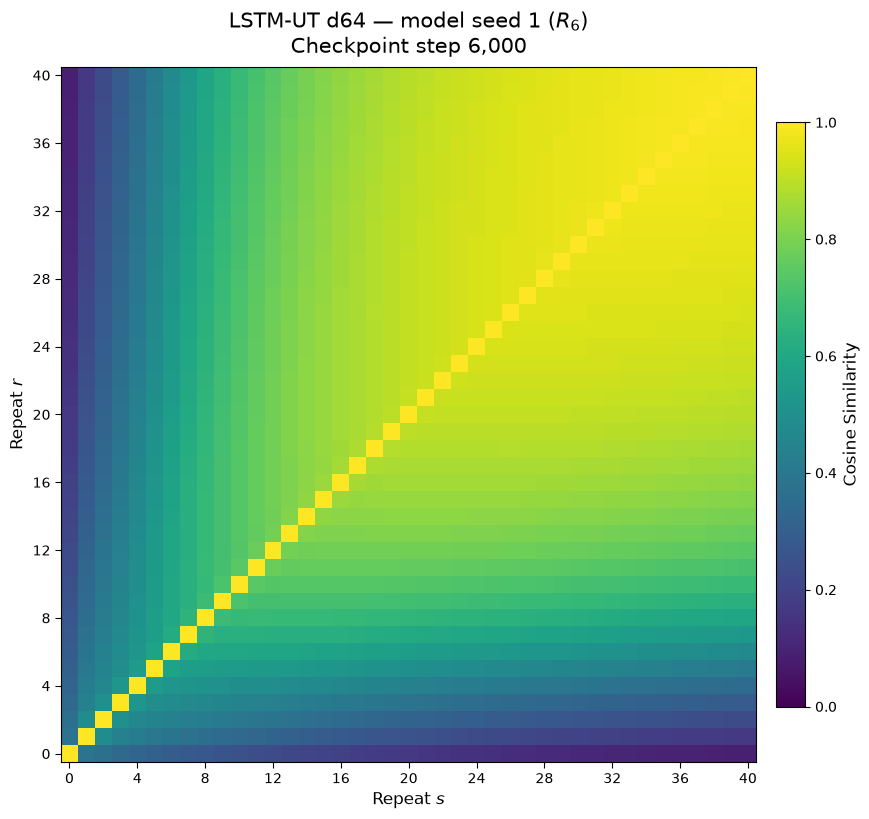

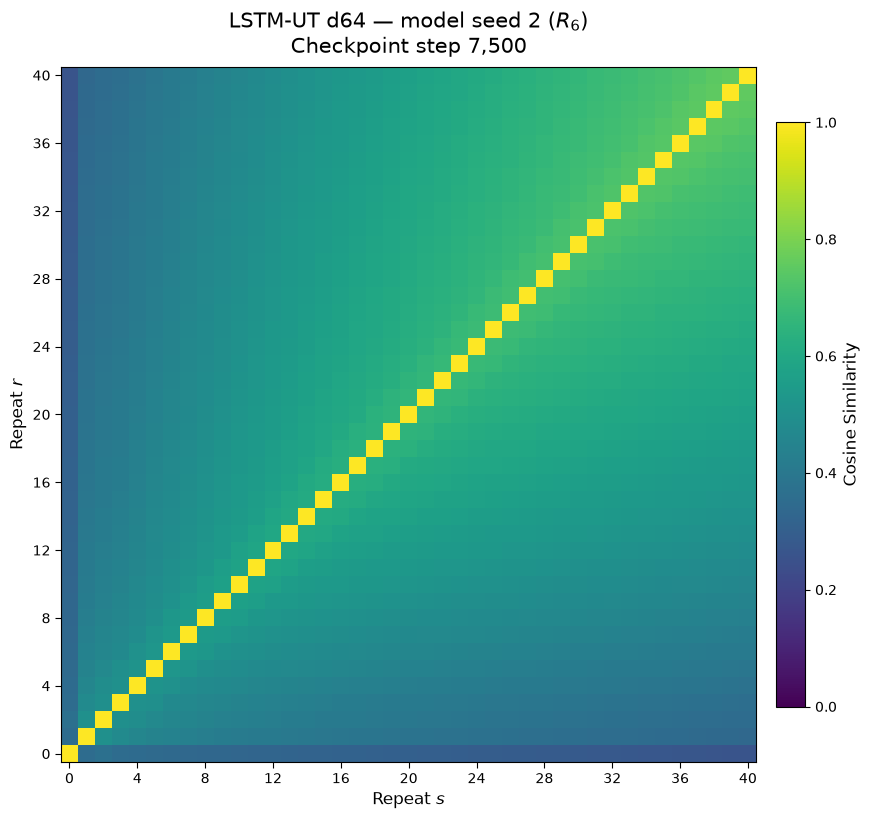

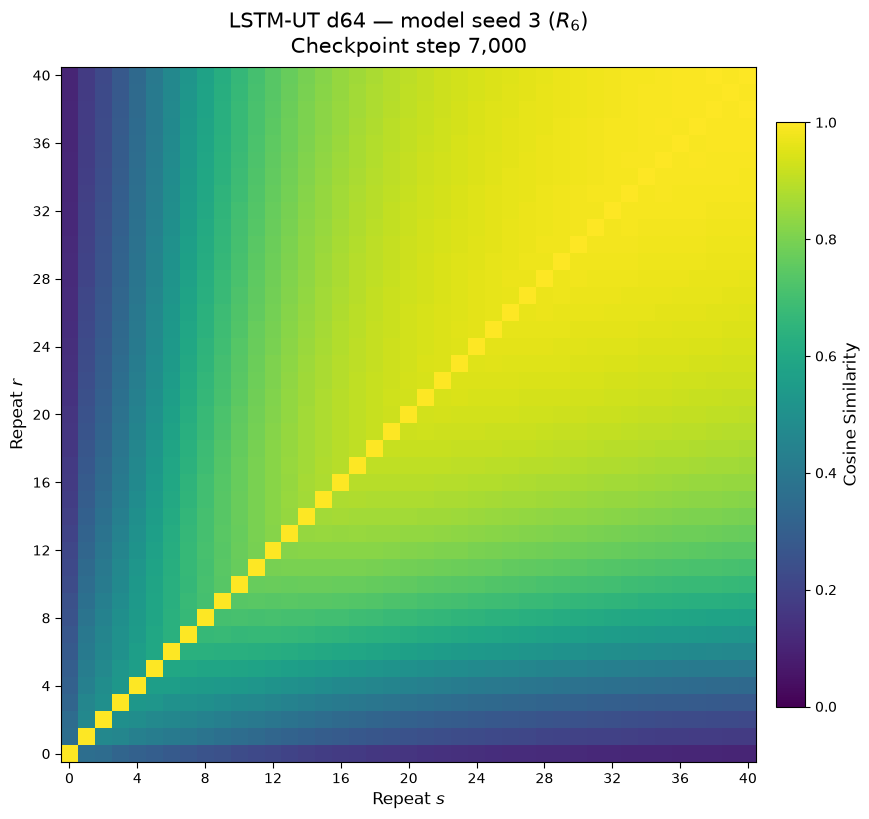

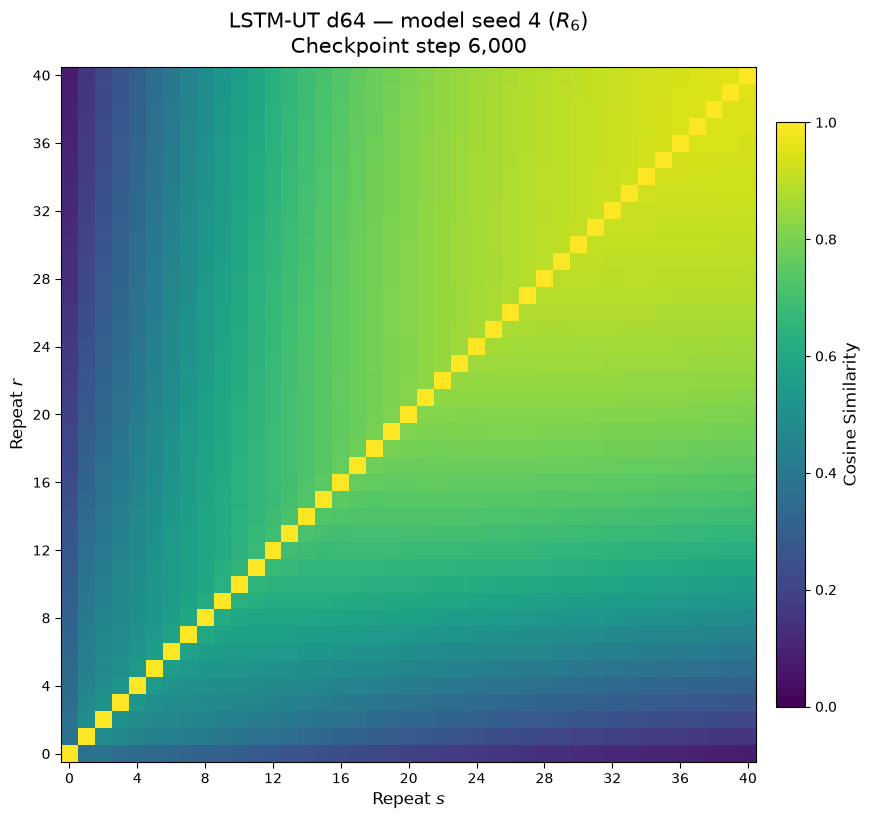

,Title,Checkpoint step,Repeats,Minimum similarity,PNG,PDF
0,LSTM-UT d32 — model seed 0 ($R_6$),5500,0–40,0.381058,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...
1,LSTM-UT d32 — model seed 1 ($R_6$),7000,0–40,0.104517,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...
2,LSTM-UT d32 — model seed 2 ($R_6$),6500,0–40,0.380449,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...
3,LSTM-UT d32 — model seed 3 ($R_6$),5500,0–40,0.372379,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...
4,LSTM-UT d32 — model seed 4 ($R_6$),6000,0–40,0.103742,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...
5,LSTM-UT d64 — model seed 0 ($R_6$),6000,0–40,0.276693,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...
6,LSTM-UT d64 — model seed 1 ($R_6$),6000,0–40,0.087206,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...
7,LSTM-UT d64 — model seed 2 ($R_6$),7500,0–40,0.257900,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...
8,LSTM-UT d64 — model seed 3 ($R_6$),7000,0–40,0.103375,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...
9,LSTM-UT d64 — model seed 4 ($R_6$),6000,0–40,0.081977,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...,/home/aras/dev/dissertation/rs-cot/lstm-ut-arx...


In [4]:
summaries = []
for specification in PLOTS:
    data, matrix, checkpoint_step = load_similarity_matrix(specification["csv"])
    png_path, pdf_path = plot_similarity_heatmap(
        matrix,
        checkpoint_step,
        specification["title"],
        specification["output_stem"],
    )
    summaries.append({
        "Title": specification["title"],
        "Checkpoint step": checkpoint_step,
        "Repeats": f"{matrix.index.min()}–{matrix.index.max()}",
        "Minimum similarity": matrix.to_numpy().min(),
        "PNG": str(png_path),
        "PDF": str(pdf_path),
    })

pd.DataFrame(summaries)

## R6 accuracy and adjacent hidden-state cosine

Each figure compares one model-initialisation seed across LSTM-UT d32, LSTM-UT d64, and BUT d64. The left column is final-test cell accuracy for the diagonal Rule 30 pair at each repeat depth. The right column is mean cosine similarity between complete hidden states at repeats $r-1$ and $r$. Both measurements use the same unconstrained extrapolation-selected checkpoint for each run. All panels use depths 1–25, the common available range. The vertical line marks the training boundary at depth 6; the horizontal line on accuracy panels marks chance-level cell accuracy. High cosine alone is not a collapse criterion.


In [3]:
# >>> RUN 3/4 FOR R6 ACCURACY + COSINE: load metrics <<<
import json

R6_RUNS = [
    ("LSTM-UT d32", [
        "run_317__ca_lstm_d32_r6_zero",
        "run_318__ca_lstm_d32_r6_zero",
        "run_319__ca_lstm_d32_r6_zero",
        "run_320__ca_lstm_d32_r6_zero",
        "run_321__ca_lstm_d32_r6_zero",
    ], "#0072B2"),
    ("LSTM-UT d64", [
        "run_34__ca_lstm_r6_zero",
        "run_44__ca_lstm_r6_zero",
        "run_54__ca_lstm_r6_zero",
        "run_64__ca_lstm_r6_zero",
        "run_74__ca_lstm_r6_zero",
    ], "#009E73"),
    ("BUT d64", [
        "run_32__ca_but_r6_zero",
        "run_42__ca_but_r6_zero",
        "run_52__ca_but_r6_zero",
        "run_62__ca_but_r6_zero",
        "run_72__ca_but_r6_zero",
    ], "#D55E00"),
]
R6_DEPTHS = np.arange(1, 26)
R6_CHECKPOINT = "best_extrapolation_unconstrained"


def load_r6_accuracy_and_cosine(run_id):
    path = REPO_ROOT / "iridis/ca-rule30/runs" / run_id / "eval_metrics.jsonl"
    accuracy = {}
    cosine = {}
    steps = set()
    for line in path.open():
        record = json.loads(line)
        if (
            record.get("checkpoint_type") != R6_CHECKPOINT
            or record.get("data_split") != "final_test"
            or record.get("length") != 64
        ):
            continue
        role = record.get("evaluation_role")
        metric = record.get("metric")
        depth = record.get("num_repeats")
        if (
            role == "repeat_horizon_diagnostic"
            and metric == "cell_accuracy"
            and depth in R6_DEPTHS
            and record.get("ca_steps") == depth
        ):
            if depth in accuracy:
                raise ValueError(f"Duplicate diagonal accuracy: {run_id}, depth {depth}")
            accuracy[depth] = float(record["value"])
            steps.add(record["step"])
        elif role == "hidden_state_similarity" and metric == "cosine_similarity":
            left = record.get("repeat_from")
            right = record.get("repeat_to")
            if left is not None and right in R6_DEPTHS and left == right - 1:
                if right in cosine:
                    raise ValueError(f"Duplicate adjacent cosine: {run_id}, depth {right}")
                cosine[right] = float(record["value"])
                steps.add(record["step"])

    expected = set(R6_DEPTHS)
    if set(accuracy) != expected or set(cosine) != expected:
        raise ValueError(
            f"Incomplete depths for {run_id}: "
            f"accuracy missing {sorted(expected - set(accuracy))}; "
            f"cosine missing {sorted(expected - set(cosine))}"
        )
    if len(steps) != 1:
        raise ValueError(f"Measurements span checkpoint steps for {run_id}: {steps}")
    accuracy_values = np.array([accuracy[depth] for depth in R6_DEPTHS])
    cosine_values = np.array([cosine[depth] for depth in R6_DEPTHS])
    if not (
        np.isfinite(accuracy_values).all()
        and np.isfinite(cosine_values).all()
        and ((0 <= accuracy_values) & (accuracy_values <= 1)).all()
        and ((-1 <= cosine_values) & (cosine_values <= 1)).all()
    ):
        raise ValueError(f"Non-finite or out-of-range measurement in {run_id}")
    return {
        "accuracy": accuracy_values,
        "cosine": cosine_values,
        "step": steps.pop(),
    }


R6_TRACES = {
    (model, seed): load_r6_accuracy_and_cosine(run_id)
    for model, run_ids, _ in R6_RUNS
    for seed, run_id in enumerate(run_ids)
}

pd.DataFrame([
    {
        "Model": model,
        "Seed": seed,
        "Checkpoint step": R6_TRACES[(model, seed)]["step"],
        "Cell accuracy @20": R6_TRACES[(model, seed)]["accuracy"][19],
        "Adjacent cosine @20": R6_TRACES[(model, seed)]["cosine"][19],
        "Cell accuracy @25": R6_TRACES[(model, seed)]["accuracy"][24],
        "Adjacent cosine @25": R6_TRACES[(model, seed)]["cosine"][24],
    }
    for model, run_ids, _ in R6_RUNS
    for seed in range(len(run_ids))
])


,Model,Seed,Checkpoint step,Cell accuracy @20,Adjacent cosine @20,Cell accuracy @25,Adjacent cosine @25
0,LSTM-UT d32,0,5500,0.991535,0.757958,0.978340,0.784915
1,LSTM-UT d32,1,7000,0.999989,0.826792,0.999962,0.869024
2,LSTM-UT d32,2,6500,0.999908,0.633988,0.999767,0.652678
3,LSTM-UT d32,3,5500,0.999580,0.721396,0.999176,0.751683
4,LSTM-UT d32,4,6000,0.998482,0.977361,0.997028,0.985310
5,LSTM-UT d64,0,6000,0.994995,0.678947,0.984375,0.705748
6,LSTM-UT d64,1,6000,0.994530,0.900529,0.973469,0.940601
7,LSTM-UT d64,2,7500,0.989967,0.650691,0.971649,0.681586
8,LSTM-UT d64,3,7000,0.969654,0.924355,0.861012,0.958276
9,LSTM-UT d64,4,6000,0.989563,0.807178,0.969421,0.863884


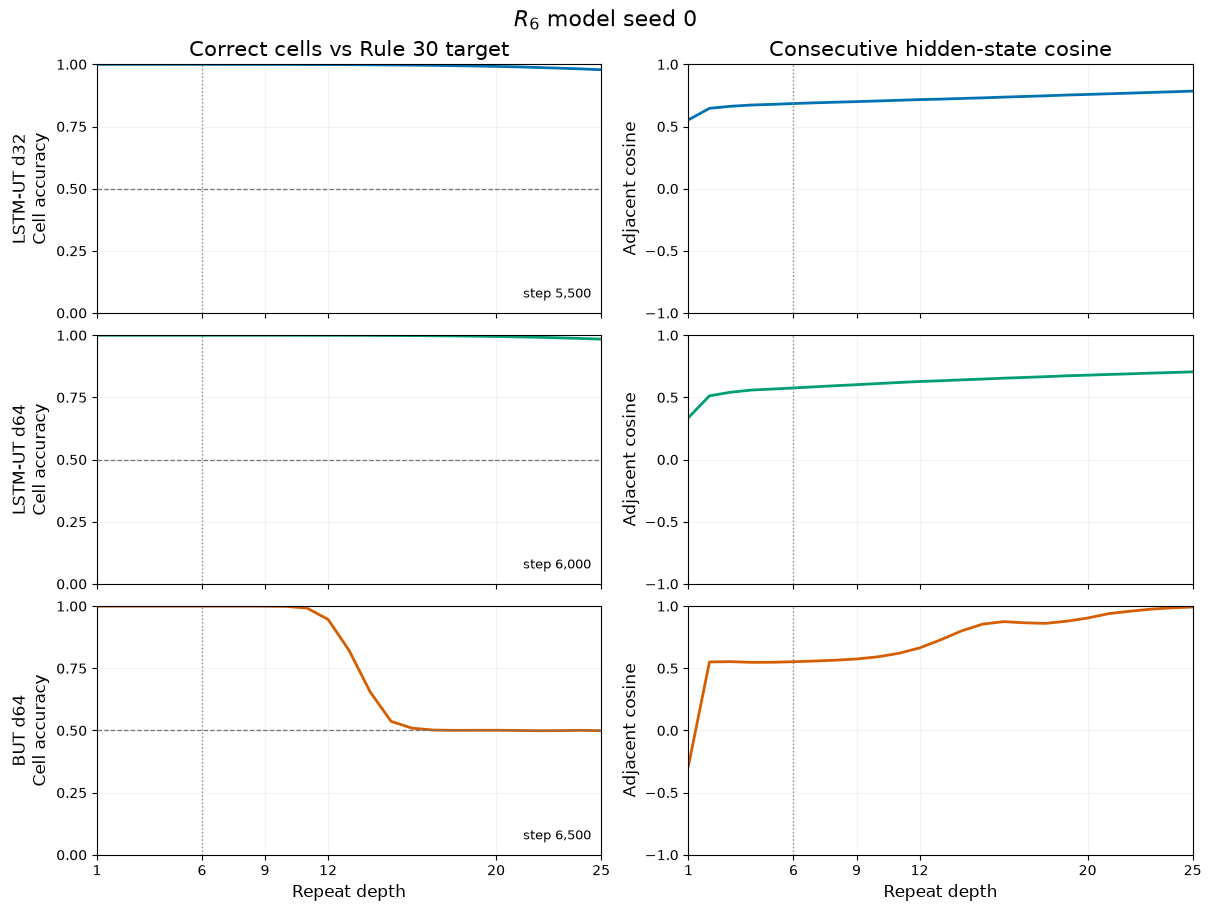

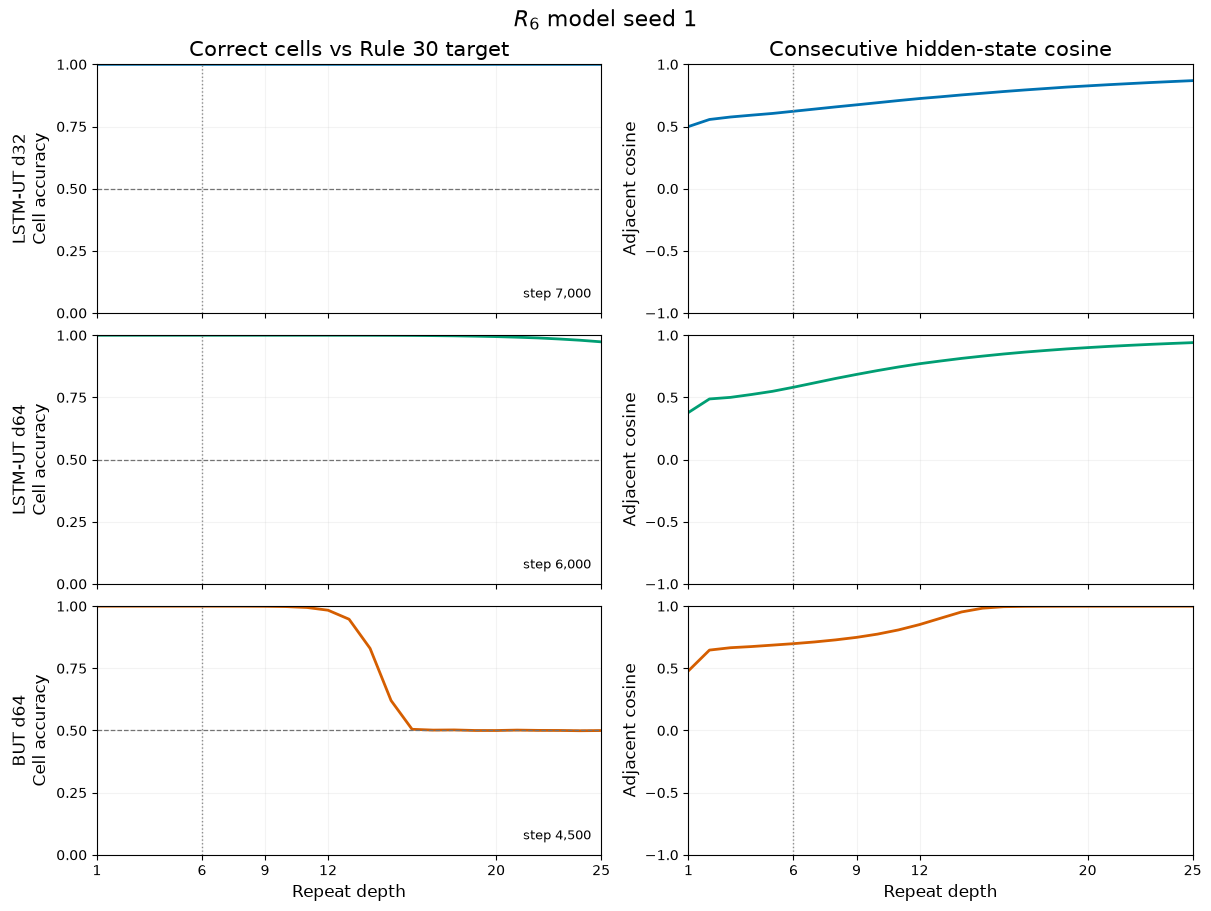

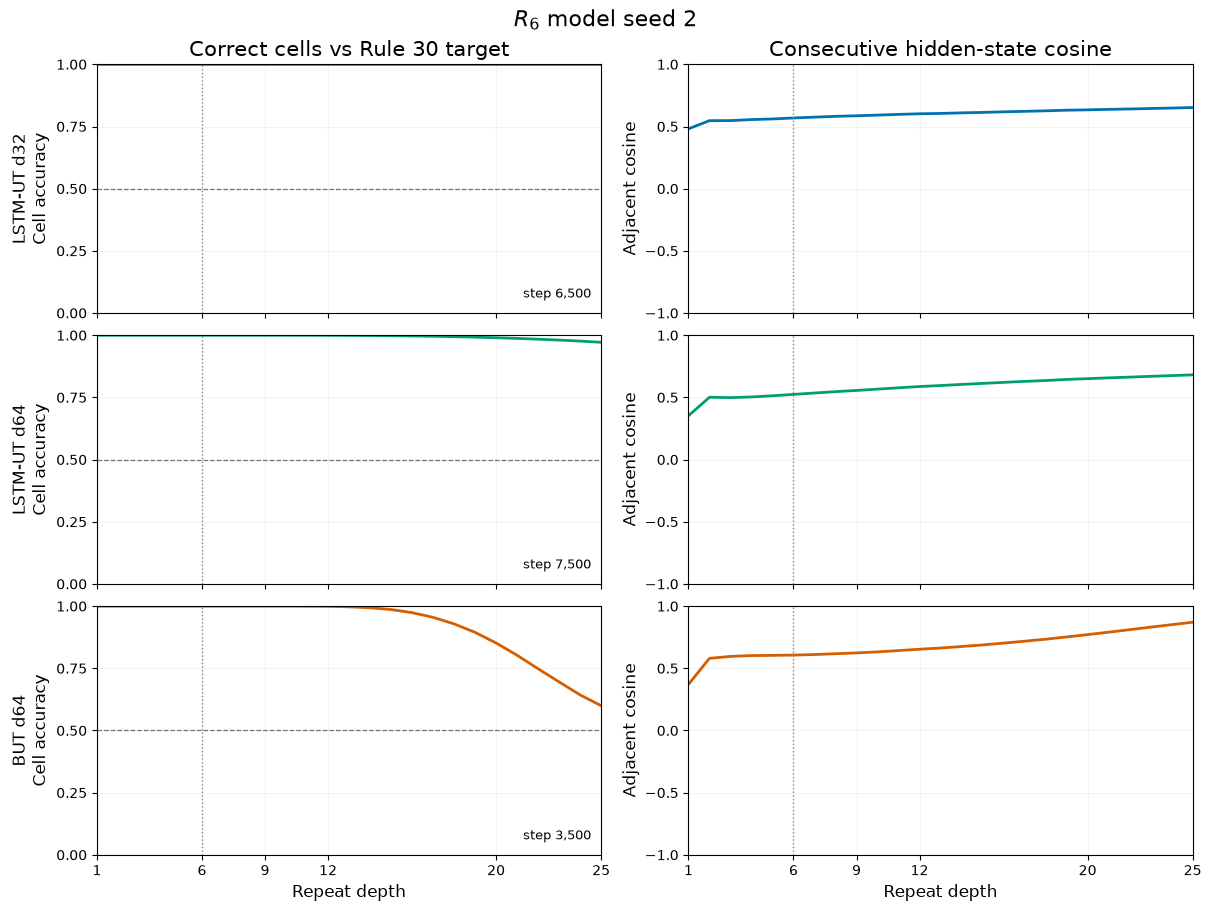

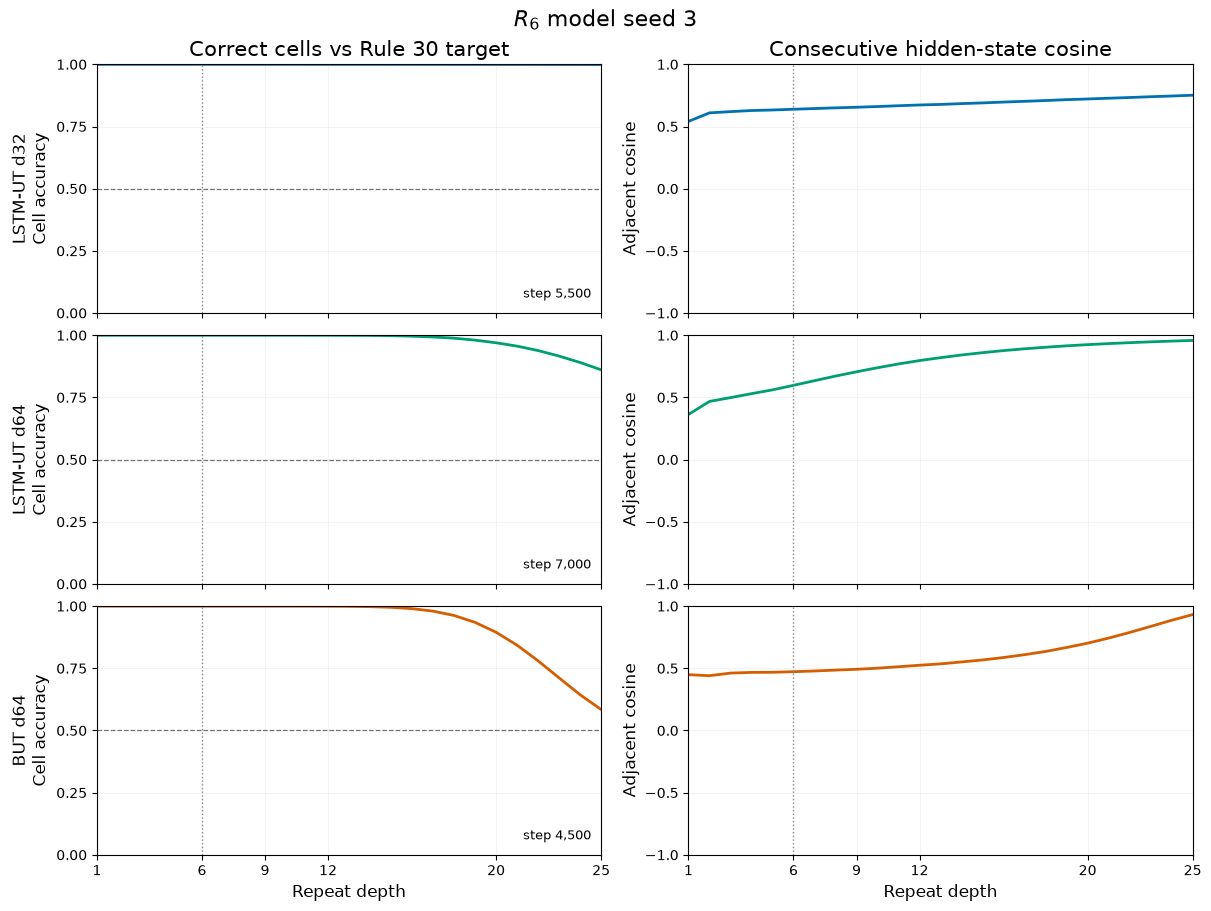

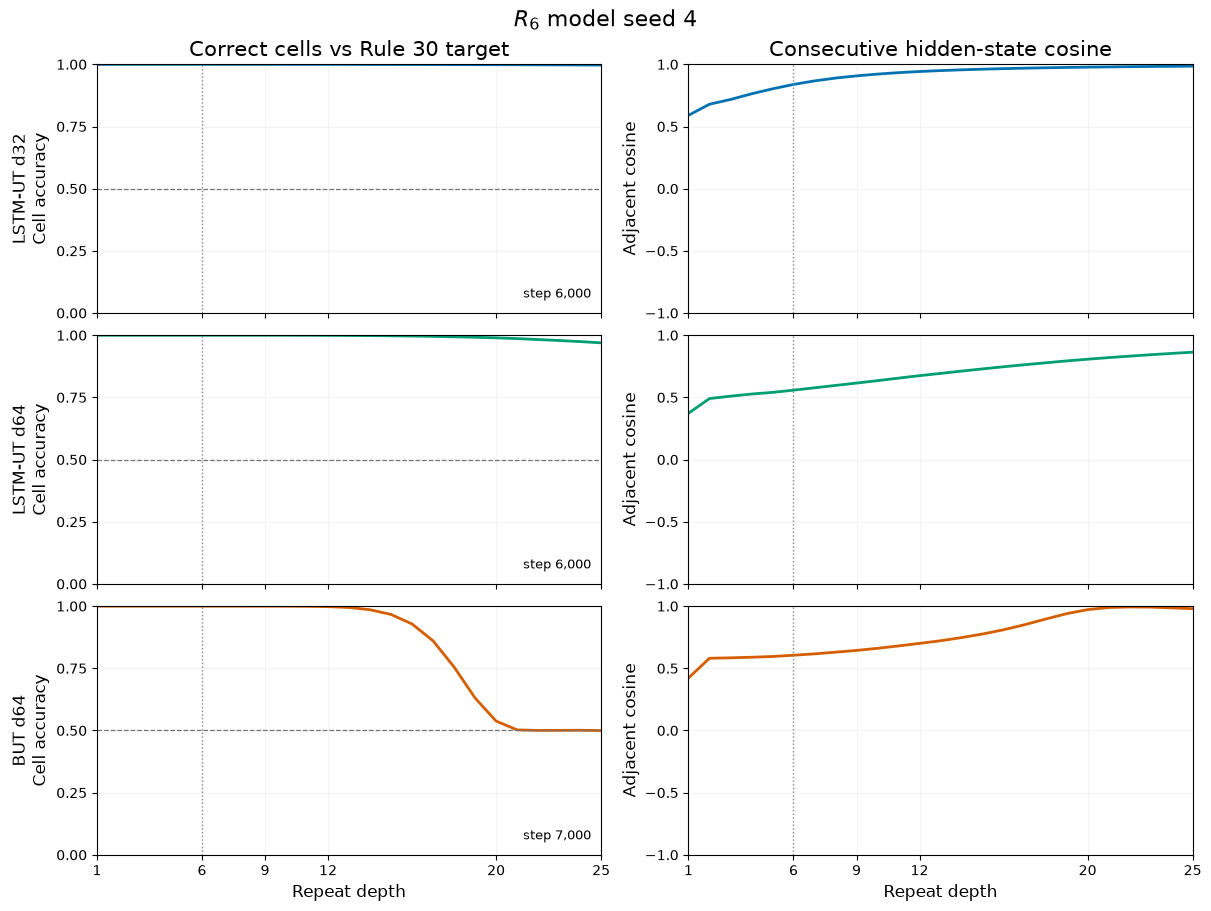

In [4]:
# >>> RUN 4/4 FOR R6 ACCURACY + COSINE: show plots <<<
for seed in range(5):
    fig, axes = plt.subplots(
        3, 2, figsize=(12, 9), sharex=True, sharey="col", constrained_layout=True
    )
    for row, (model, _, color) in enumerate(R6_RUNS):
        trace = R6_TRACES[(model, seed)]
        accuracy_ax, cosine_ax = axes[row]
        accuracy_ax.plot(R6_DEPTHS, trace["accuracy"], color=color, lw=2)
        cosine_ax.plot(R6_DEPTHS, trace["cosine"], color=color, lw=2)
        accuracy_ax.axhline(0.5, color="0.45", ls="--", lw=0.9)
        for ax in (accuracy_ax, cosine_ax):
            ax.axvline(6, color="0.55", ls=":", lw=1)
            ax.set_xlim(1, 25)
            ax.set_xticks([1, 6, 9, 12, 20, 25])
            ax.grid(alpha=0.15)
        accuracy_ax.set_ylim(0, 1)
        accuracy_ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
        cosine_ax.set_ylim(-1, 1)
        cosine_ax.set_yticks([-1, -0.5, 0, 0.5, 1])
        accuracy_ax.set_ylabel(f"{model}\nCell accuracy")
        cosine_ax.set_ylabel("Adjacent cosine")
        accuracy_ax.text(
            0.98, 0.05, f"step {trace['step']:,}",
            transform=accuracy_ax.transAxes, ha="right", va="bottom", fontsize=9
        )
    axes[0, 0].set_title("Correct cells vs Rule 30 target")
    axes[0, 1].set_title("Consecutive hidden-state cosine")
    axes[-1, 0].set_xlabel("Repeat depth")
    axes[-1, 1].set_xlabel("Repeat depth")
    fig.suptitle(f"$R_6$ model seed {seed}", fontsize=16)
    plt.show()
    plt.close(fig)


## Publication-ready factorial intervention outcomes

This section reads one compact `summary.json` at a time and never opens the multi-gigabyte factorial shards. It produces uniquely named paper figures without modifying the original downloaded plots.

In [10]:
import json
import re


FACTORIAL_RUN_DIR = (
    REPO_ROOT
    / "downloads"
    / "ca-intervene"
    / "factorial-grid"
    / "factorial-grid"
    / "run_95__ca_cotf_cache_attn"
)
FACTORIAL_SOURCE_DEPTHS = tuple(range(16, 24))
FACTORIAL_OUTPUT_DIR = REPO_ROOT / "dis-draft" / "dis-images" / "ca-interventions"
MAX_FACTORIAL_SUMMARY_BYTES = 5 * 1024 * 1024

FACTORIAL_CONDITION_LABELS = {
    "free_baseline": "Free baseline",
    "clean_baseline": "Clean baseline",
    "free_reset": "Free reset",
    "clean_reset": "Clean reset",
}
FACTORIAL_CONDITION_COLORS = {
    "free_baseline": "#4C78A8",
    "clean_baseline": "#F58518",
    "free_reset": "#54A24B",
    "clean_reset": "#E45756",
}
FACTORIAL_CONDITION_STYLES = {
    # Solid, larger baseline markers remain visible beneath the narrower reset traces.
    "free_baseline": {"linestyle": "-", "marker": "o", "markersize": 6.5, "linewidth": 2.4, "zorder": 2},
    "clean_baseline": {"linestyle": "-", "marker": "D", "markersize": 6.0, "linewidth": 2.2, "zorder": 3},
    "free_reset": {"linestyle": (0, (5, 3)), "marker": "^", "markersize": 4.8, "linewidth": 1.8, "zorder": 4},
    "clean_reset": {"linestyle": (0, (1.5, 2.2)), "marker": "s", "markersize": 4.3, "linewidth": 1.8, "zorder": 5},
}
FACTORIAL_MODEL_LABELS = {"ca_cotf_cache_attn": "CoTFormer"}
FACTORIAL_PLOT_METRICS = (
    ("cell_accuracy", "Cell accuracy", (0.45, 1.01)),
    ("exact_sequence_accuracy", "Exact-sequence accuracy", (-0.02, 1.02)),
)


def load_factorial_outcomes(summary_path, expected_source_depth):
    summary_path = Path(summary_path)
    if not summary_path.is_file():
        raise FileNotFoundError(f"Missing factorial summary: {summary_path}")
    if summary_path.stat().st_size > MAX_FACTORIAL_SUMMARY_BYTES:
        raise ValueError(f"Refusing to load unexpectedly large summary: {summary_path}")

    # The summary is small (tens of KiB); it is released before the next source is read.
    with summary_path.open(encoding="utf-8") as handle:
        summary = json.load(handle)

    evaluation = summary.get("factorial_full_split_evaluation")
    if not isinstance(evaluation, dict):
        raise ValueError(f"Missing full-split factorial evaluation: {summary_path}")
    source_depth = evaluation.get("source_depth")
    if source_depth != expected_source_depth:
        raise ValueError(
            f"Expected intervention depth {expected_source_depth}, found {source_depth}"
        )
    target_depths = evaluation.get("target_depths")
    max_repeats = evaluation.get("max_repeats")
    if target_depths != list(range(source_depth + 1, max_repeats + 1)):
        raise ValueError(f"Invalid target-depth coverage: {summary_path}")

    conditions = evaluation.get("conditions")
    if not isinstance(conditions, dict) or set(conditions) != set(FACTORIAL_CONDITION_LABELS):
        raise ValueError(f"Expected exactly four factorial conditions: {summary_path}")
    curves = {}
    for condition_id in FACTORIAL_CONDITION_LABELS:
        by_depth = conditions[condition_id].get("by_target_depth", {})
        if set(by_depth) != {str(depth) for depth in target_depths}:
            raise ValueError(f"Inconsistent depths for {condition_id}: {summary_path}")
        curves[condition_id] = {
            metric: [float(by_depth[str(depth)][metric]) for depth in target_depths]
            for metric, _, _ in FACTORIAL_PLOT_METRICS
        }

    run_id = summary.get("run_id", "")
    run_match = re.fullmatch(r"run_(\d+)__.+", run_id)
    if run_match is None:
        raise ValueError(f"Invalid run ID: {run_id!r}")
    model_name = summary.get("diagnostic_model")
    if not isinstance(model_name, str) or not model_name:
        raise ValueError(f"Missing model name: {summary_path}")
    trained_window = evaluation.get("trained_cache_window")
    if trained_window is None:
        cache_policy = "full"
    elif isinstance(trained_window, int) and not isinstance(trained_window, bool) and trained_window > 0:
        cache_policy = f"recent {trained_window}"
    else:
        raise ValueError(f"Invalid trained cache window: {trained_window!r}")

    return {
        "run_number": int(run_match.group(1)),
        "model_name": FACTORIAL_MODEL_LABELS.get(model_name, model_name),
        "cache_policy": cache_policy,
        "source_depth": source_depth,
        "target_depths": target_depths,
        "curves": curves,
    }


def plot_factorial_outcomes(outcomes, shared_baseline):
    fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.6), constrained_layout=True)
    for axis, (metric, label, limits) in zip(axes, FACTORIAL_PLOT_METRICS):
        prefix_indices = [
            index
            for index, depth in enumerate(shared_baseline["target_depths"])
            if depth <= outcomes["source_depth"]
        ]
        if prefix_indices:
            axis.plot(
                [shared_baseline["target_depths"][index] for index in prefix_indices],
                [shared_baseline["curves"][metric][index] for index in prefix_indices],
                marker="o",
                markersize=4,
                linewidth=1.8,
                color="#777777",
                label="Shared pre-intervention trajectory",
            )
        for condition_id, display_label in FACTORIAL_CONDITION_LABELS.items():
            axis.plot(
                outcomes["target_depths"],
                outcomes["curves"][condition_id][metric],
                color=FACTORIAL_CONDITION_COLORS[condition_id],
                label=display_label,
                **FACTORIAL_CONDITION_STYLES[condition_id],
            )
        axis.set(
            xlabel="Target depth",
            ylabel=label,
            title=label,
            ylim=limits,
        )
        axis.grid(alpha=0.18, linewidth=0.6)
    axes[0].legend(fontsize=9, frameon=False)

    title = (
        f"Run {outcomes['run_number']} · {outcomes['model_name']} · "
        f"trained cache: {outcomes['cache_policy']}\n"
        f"Intervention depth {outcomes['source_depth']}"
    )
    fig.suptitle(title)
    FACTORIAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    policy_slug = outcomes["cache_policy"].replace(" ", "-")
    output_stem = (
        f"run-{outcomes['run_number']}-{policy_slug}-"
        f"t{outcomes['source_depth']}-factorial-outcomes"
    )
    png_path = FACTORIAL_OUTPUT_DIR / f"{output_stem}.png"
    pdf_path = FACTORIAL_OUTPUT_DIR / f"{output_stem}.pdf"
    fig.savefig(png_path, dpi=OUTPUT_DPI, bbox_inches="tight", facecolor="white")
    fig.savefig(pdf_path, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
    return png_path, pdf_path

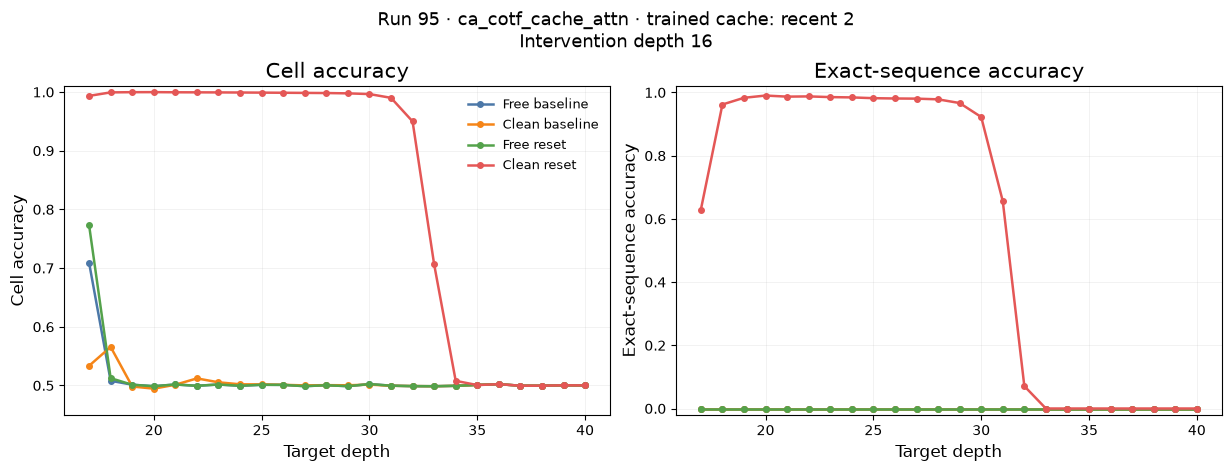

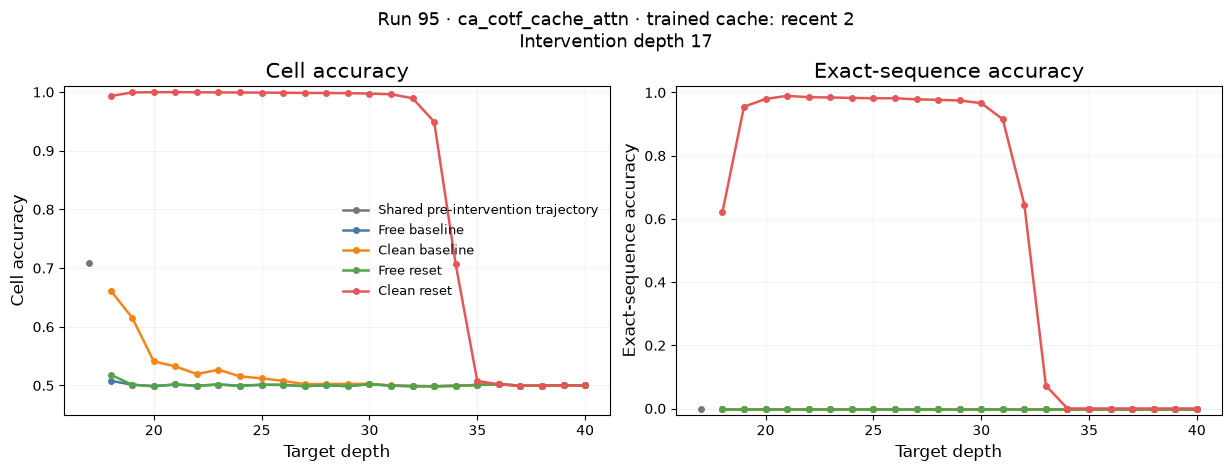

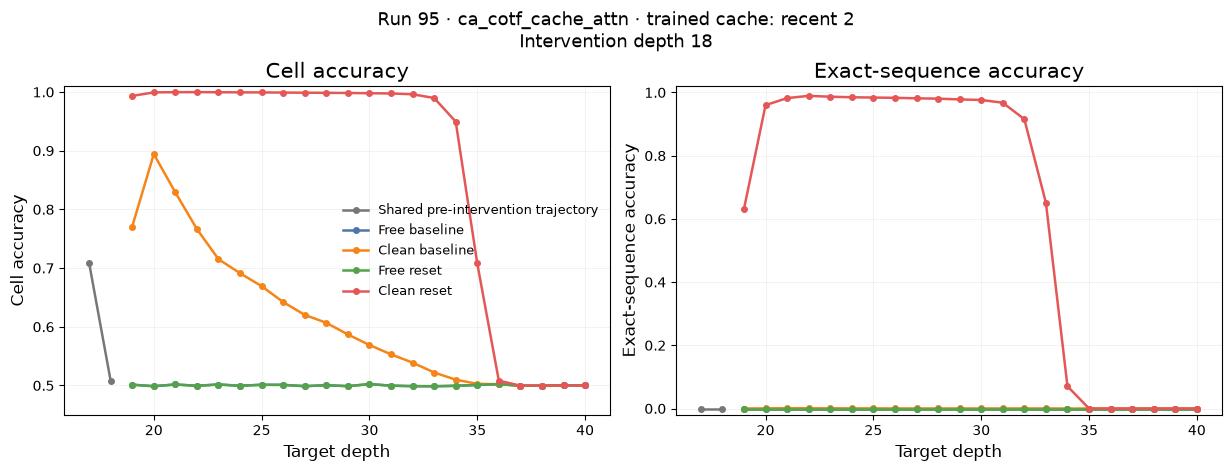

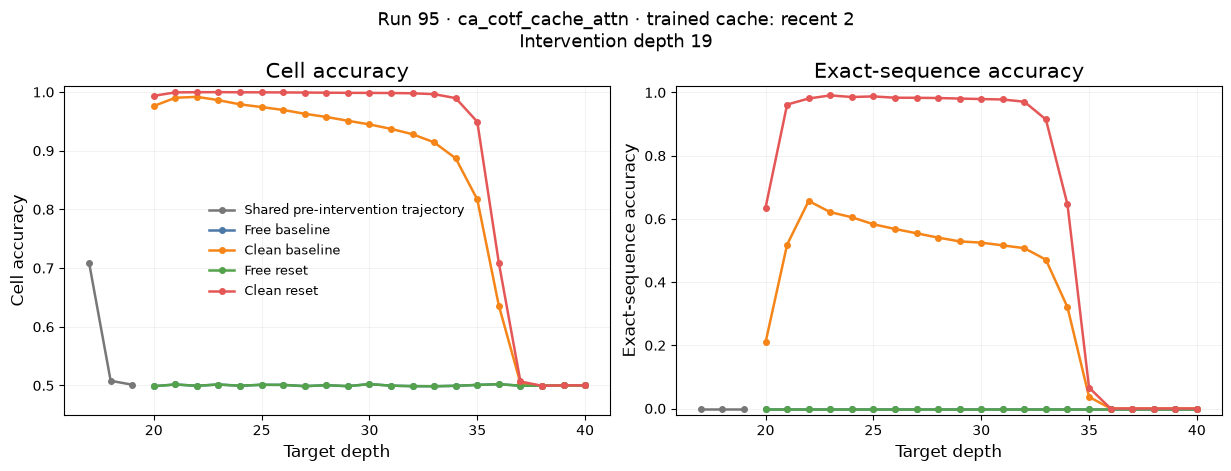

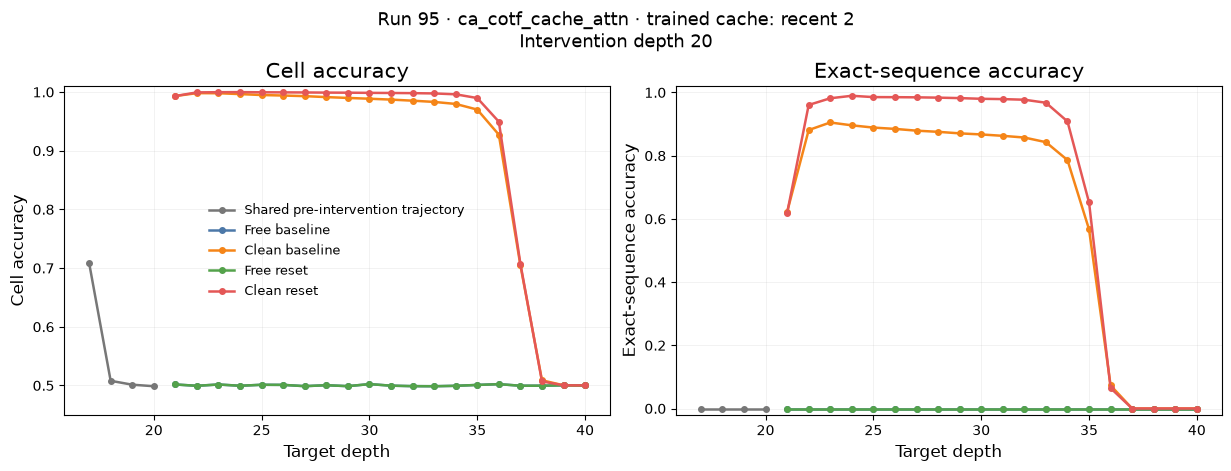

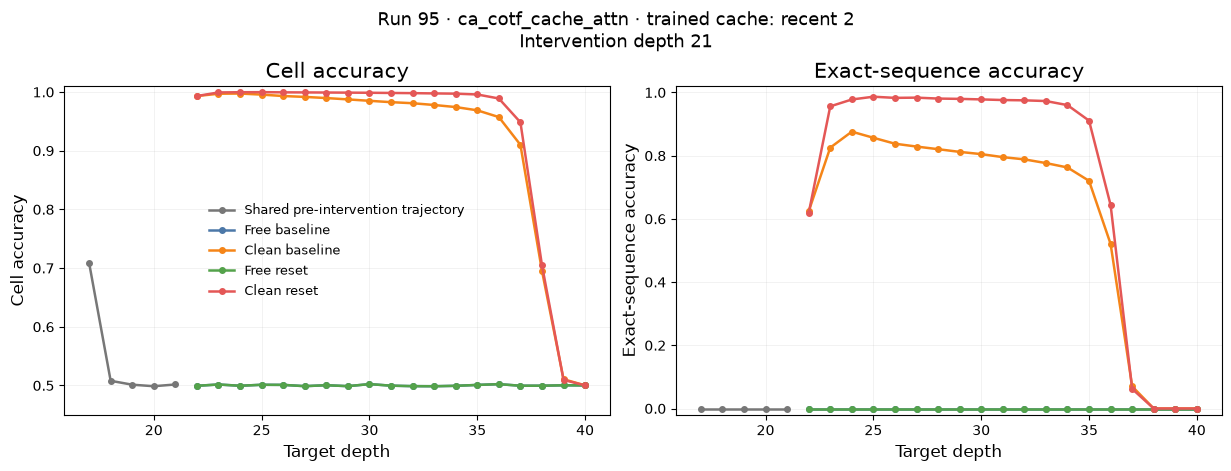

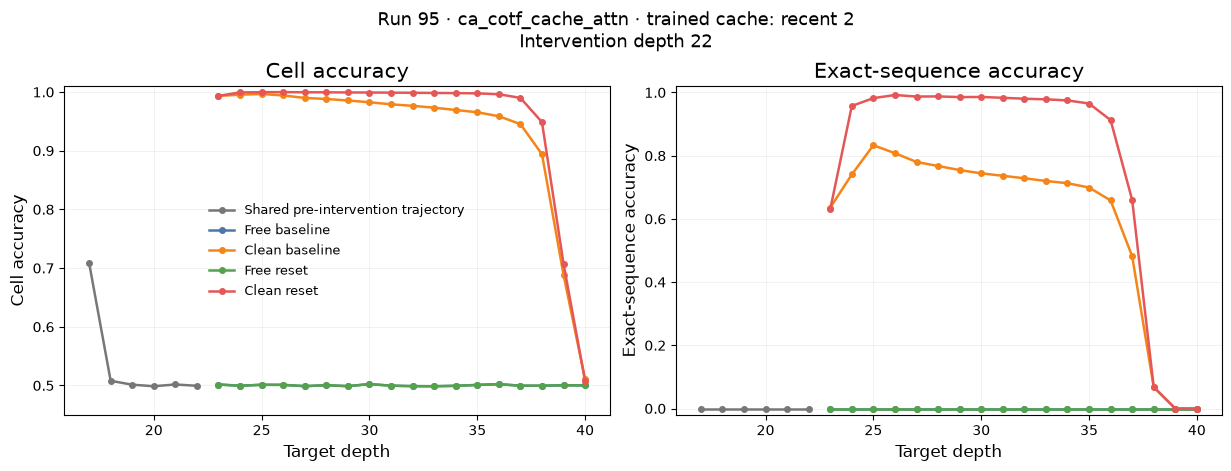

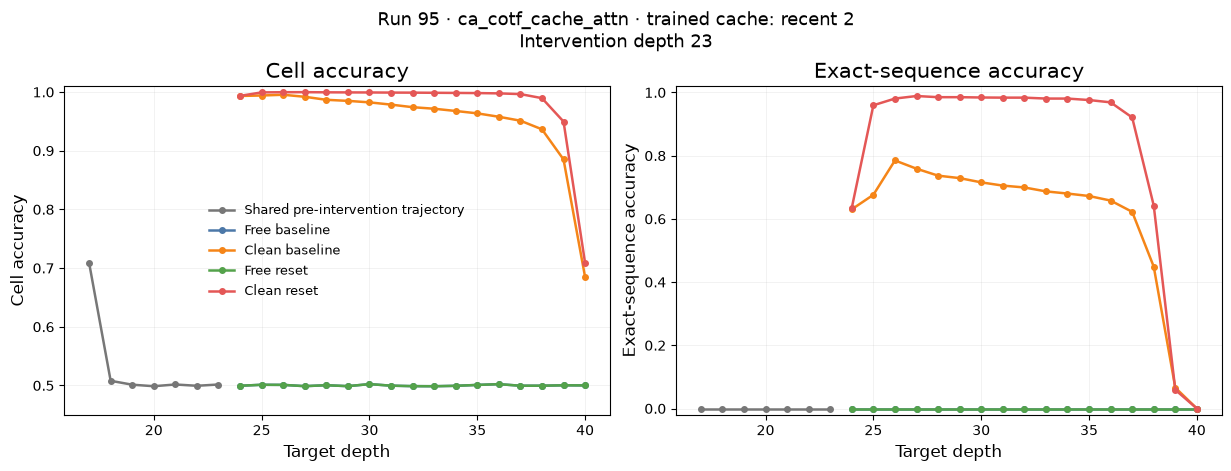

,Run,Model,Trained cache,Intervention depth,Targets,PNG,PDF
0,95,ca_cotf_cache_attn,recent 2,16,17–40,/home/aras/dev/dissertation/rs-cot/dis-draft/d...,/home/aras/dev/dissertation/rs-cot/dis-draft/d...
1,95,ca_cotf_cache_attn,recent 2,17,18–40,/home/aras/dev/dissertation/rs-cot/dis-draft/d...,/home/aras/dev/dissertation/rs-cot/dis-draft/d...
2,95,ca_cotf_cache_attn,recent 2,18,19–40,/home/aras/dev/dissertation/rs-cot/dis-draft/d...,/home/aras/dev/dissertation/rs-cot/dis-draft/d...
3,95,ca_cotf_cache_attn,recent 2,19,20–40,/home/aras/dev/dissertation/rs-cot/dis-draft/d...,/home/aras/dev/dissertation/rs-cot/dis-draft/d...
4,95,ca_cotf_cache_attn,recent 2,20,21–40,/home/aras/dev/dissertation/rs-cot/dis-draft/d...,/home/aras/dev/dissertation/rs-cot/dis-draft/d...
5,95,ca_cotf_cache_attn,recent 2,21,22–40,/home/aras/dev/dissertation/rs-cot/dis-draft/d...,/home/aras/dev/dissertation/rs-cot/dis-draft/d...
6,95,ca_cotf_cache_attn,recent 2,22,23–40,/home/aras/dev/dissertation/rs-cot/dis-draft/d...,/home/aras/dev/dissertation/rs-cot/dis-draft/d...
7,95,ca_cotf_cache_attn,recent 2,23,24–40,/home/aras/dev/dissertation/rs-cot/dis-draft/d...,/home/aras/dev/dissertation/rs-cot/dis-draft/d...


In [12]:
reference_path = FACTORIAL_RUN_DIR / "t16" / "summary.json"
reference_outcomes = load_factorial_outcomes(reference_path, 16)
shared_baseline = {
    "target_depths": reference_outcomes["target_depths"],
    "curves": reference_outcomes["curves"]["free_baseline"],
}
del reference_outcomes

factorial_plot_summaries = []
for source_depth in FACTORIAL_SOURCE_DEPTHS:
    summary_path = FACTORIAL_RUN_DIR / f"t{source_depth}" / "summary.json"
    outcomes = load_factorial_outcomes(summary_path, source_depth)
    png_path, pdf_path = plot_factorial_outcomes(outcomes, shared_baseline)
    factorial_plot_summaries.append({
        "Run": outcomes["run_number"],
        "Model": outcomes["model_name"],
        "Trained cache": outcomes["cache_policy"],
        "Intervention depth": outcomes["source_depth"],
        "Targets": f"{outcomes['target_depths'][0]}–{outcomes['target_depths'][-1]}",
        "PNG": str(png_path),
        "PDF": str(pdf_path),
    })
    del outcomes

pd.DataFrame(factorial_plot_summaries)

In [1]:
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


## Publication-ready delayed-recall figures

This section generates the three delayed-recall figures used in the dissertation. It reads the compact comparison reports for the overview and paired-repeat plots. The representative horizon-12 diagnostic streams the selected evaluation files once per run so that changed-cell accuracy is computed from per-run measurements rather than approximated from aggregated CSV rows. Plot labels use only paper-facing terminology.

In [7]:
from types import SimpleNamespace

from ca_analyze import (
    DELAYED_METRICS,
    collect_delayed_run,
    discover_runs,
)


DELAYED_REPORT_ROOT = REPO_ROOT / "iridis" / "dca-30" / "reports" / "dissertation-delayed"
DELAYED_RUN_ROOT = REPO_ROOT / "iridis" / "dca-30" / "runs"
DELAYED_OUTPUT_DIR = REPO_ROOT / "dis-draft" / "dis-images" / "delayed-recall"
DELAYED_HORIZONS = (6, 12, 20, 30)
MODEL_ORDER = ("dca_but", "dca_cotf_cache")
MODEL_LABELS = {"dca_but": "BUT", "dca_cotf_cache": "CoTFormer"}
MODEL_COLORS = {"dca_but": "#4C78A8", "dca_cotf_cache": "#E45756"}
RECALL_LABELS = {1: "One recall application", 2: "Two recall applications"}


def save_delayed_figure(fig, output_stem):
    DELAYED_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    png_path = DELAYED_OUTPUT_DIR / f"{output_stem}.png"
    pdf_path = DELAYED_OUTPUT_DIR / f"{output_stem}.pdf"
    fig.savefig(png_path, dpi=OUTPUT_DPI, bbox_inches="tight", facecolor="white")
    fig.savefig(pdf_path, bbox_inches="tight", facecolor="white")
    return png_path, pdf_path


def read_delayed_summary(recall_applications, horizon):
    path = DELAYED_REPORT_ROOT / f"recall{recall_applications}_h{horizon}" / "delayed_summary.csv"
    data = pd.read_csv(path)
    selected = data[data["metric"].eq("cell_accuracy")].copy()
    if set(selected["model"]) != set(MODEL_ORDER) or len(selected) != 2:
        raise ValueError(f"Expected one delayed-recall summary for each architecture: {path}")
    selected["recall_applications"] = recall_applications
    selected["maximum_horizon"] = horizon
    return selected


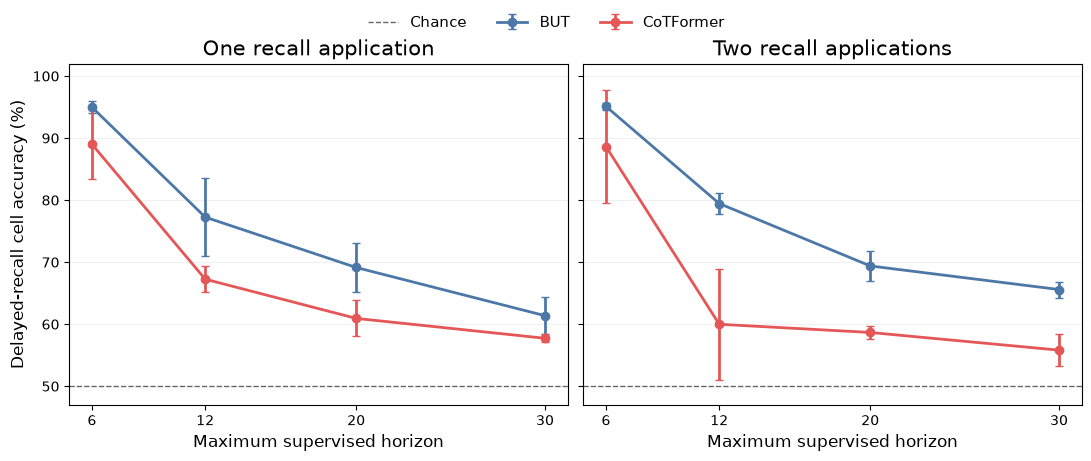

(PosixPath('/home/aras/dev/rs-cot/dis-draft/dis-images/delayed-recall/delayed-recall-overview.png'),
 PosixPath('/home/aras/dev/rs-cot/dis-draft/dis-images/delayed-recall/delayed-recall-overview.pdf'))

In [8]:
overview_data = pd.concat(
    [
        read_delayed_summary(recall_applications, horizon)
        for recall_applications in (1, 2)
        for horizon in DELAYED_HORIZONS
    ],
    ignore_index=True,
)

fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.2), sharey=True, constrained_layout=True)
for axis, recall_applications in zip(axes, (1, 2)):
    panel = overview_data[overview_data["recall_applications"].eq(recall_applications)]
    for model in MODEL_ORDER:
        values = panel[panel["model"].eq(model)].sort_values("maximum_horizon")
        axis.errorbar(
            values["maximum_horizon"],
            100 * values["mean"],
            yerr=100 * values["std"],
            marker="o",
            markersize=6,
            linewidth=2,
            capsize=3,
            color=MODEL_COLORS[model],
            label=MODEL_LABELS[model],
        )
    axis.axhline(50, color="#666666", linestyle="--", linewidth=1, label="Chance")
    axis.set(
        title=RECALL_LABELS[recall_applications],
        xlabel="Maximum supervised horizon",
        xticks=DELAYED_HORIZONS,
        ylim=(47, 102),
    )
    axis.grid(axis="y", alpha=0.2, linewidth=0.7)
axes[0].set_ylabel("Delayed-recall cell accuracy (%)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.08))
overview_paths = save_delayed_figure(fig, "delayed-recall-overview")
plt.show()
plt.close(fig)
overview_paths

In [9]:
# These are the exact matched horizon-12 run groups recorded by the analysis manifests.
H12_RUN_IDS = {
    (1, "dca_but"): (
        "run_61__dca_but_h12_recall1_allquery_ckpt",
        "run_62__dca_but_h12_recall1_allquery_ckpt",
        "run_63__dca_but_h12_recall1_allquery_ckpt",
    ),
    (1, "dca_cotf_cache"): (
        "run_70__dca_cotf_h12_recall1_allquery_ckpt",
        "run_71__dca_cotf_h12_recall1_allquery_ckpt",
        "run_72__dca_cotf_h12_recall1_allquery_ckpt",
    ),
    (2, "dca_but"): (
        "run_40__dca_but_h12_recall2_allquery_ckpt",
        "run_41__dca_but_h12_recall2_allquery_ckpt",
        "run_42__dca_but_h12_recall2_allquery_ckpt",
    ),
    (2, "dca_cotf_cache"): (
        "run_43__dca_cotf_h12_recall2_allquery_ckpt",
        "run_44__dca_cotf_h12_recall2_allquery_ckpt",
        "run_45__dca_cotf_h12_recall2_allquery_ckpt",
    ),
}

H12_METRICS = (
    "internal_cell_accuracy",
    "internal_changed_cell_accuracy",
    "cosine_unique_best_rate",
    "cosine_rank",
)
h12_specs = {name: DELAYED_METRICS[name] for name in H12_METRICS}
h12_arguments = SimpleNamespace(length=64, split="final_test", checkpoint="best_delayed_recall")
available_runs = {run.run_id: run for run in discover_runs(DELAYED_RUN_ROOT, load_metrics=False)}

h12_rows = []
for (recall_applications, model), run_ids in H12_RUN_IDS.items():
    for run_id in run_ids:
        run = available_runs.get(run_id)
        if run is None:
            raise FileNotFoundError(f"Missing delayed-recall run: {run_id}")
        run_data = collect_delayed_run(run, h12_arguments, h12_specs)
        for metric in H12_METRICS:
            measurement = run_data["horizons"].get((12, metric))
            if measurement is None:
                raise ValueError(f"Missing horizon-12 {metric} measurement for {run_id}")
            h12_rows.append({
                "Recall applications": recall_applications,
                "Model": model,
                "Metric": metric,
                "Value": measurement["value"],
                "Checkpoint step": measurement["step"],
            })

h12_data = pd.DataFrame(h12_rows)
h12_summary = (
    h12_data.groupby(["Recall applications", "Model", "Metric"], as_index=False)
    .agg(Mean=("Value", "mean"), SD=("Value", "std"), Seeds=("Value", "size"))
)
if not h12_summary["Seeds"].eq(3).all():
    raise ValueError("Every horizon-12 diagnostic must contain exactly three model seeds.")


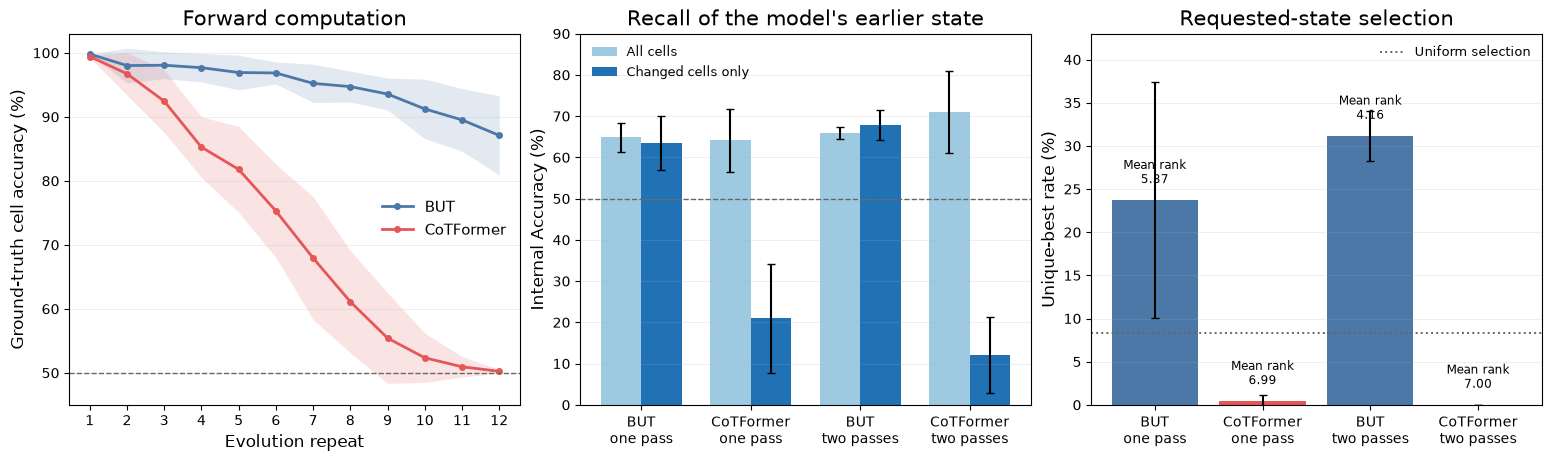

(PosixPath('/home/aras/dev/rs-cot/dis-draft/dis-images/delayed-recall/delayed-recall-h12-selection.png'),
 PosixPath('/home/aras/dev/rs-cot/dis-draft/dis-images/delayed-recall/delayed-recall-h12-selection.pdf'))

In [10]:
forward_path = DELAYED_REPORT_ROOT / "recall1_h12" / "delayed_horizons.csv"
forward_data = pd.read_csv(forward_path)
forward_data = forward_data[
    forward_data["scope"].eq("in_distribution_same_checkpoint")
    & forward_data["metric"].eq("cell_accuracy")
].copy()

fig, axes = plt.subplots(1, 3, figsize=(15.4, 4.5), constrained_layout=True)
for model in MODEL_ORDER:
    values = forward_data[forward_data["model"].eq(model)].sort_values("horizon")
    x = values["horizon"].to_numpy()
    mean = 100 * values["mean"].to_numpy()
    sd = 100 * values["std"].to_numpy()
    axes[0].plot(x, mean, marker="o", markersize=4, linewidth=2, color=MODEL_COLORS[model], label=MODEL_LABELS[model])
    axes[0].fill_between(x, mean - sd, mean + sd, color=MODEL_COLORS[model], alpha=0.16, linewidth=0)
axes[0].axhline(50, color="#666666", linestyle="--", linewidth=1)
axes[0].set(title="Forward computation", xlabel="Evolution repeat", ylabel="Ground-truth cell accuracy (%)", xticks=range(1, 13), ylim=(45, 103))
axes[0].legend(frameon=False)
axes[0].grid(axis="y", alpha=0.2, linewidth=0.7)

category_keys = ((1, "dca_but"), (1, "dca_cotf_cache"), (2, "dca_but"), (2, "dca_cotf_cache"))
category_labels = ("BUT\none pass", "CoTFormer\none pass", "BUT\ntwo passes", "CoTFormer\ntwo passes")
x = np.arange(len(category_keys))
bar_width = 0.37
accuracy_metrics = (
    ("internal_cell_accuracy", "All cells", "#9ECAE1"),
    ("internal_changed_cell_accuracy", "Changed cells only", "#2171B5"),
)
for offset, (metric, label, color) in zip((-bar_width / 2, bar_width / 2), accuracy_metrics):
    means, errors = [], []
    for recall_applications, model in category_keys:
        row = h12_summary[
            h12_summary["Recall applications"].eq(recall_applications)
            & h12_summary["Model"].eq(model)
            & h12_summary["Metric"].eq(metric)
        ].iloc[0]
        means.append(100 * row["Mean"])
        errors.append(100 * row["SD"])
    axes[1].bar(x + offset, means, bar_width, yerr=errors, capsize=3, color=color, label=label)
axes[1].axhline(50, color="#666666", linestyle="--", linewidth=1)
axes[1].set(title="Recall of the model's earlier state", ylabel="Internal Accuracy (%)", xticks=x, xticklabels=category_labels, ylim=(0, 90))
axes[1].legend(frameon=False, fontsize=9)
axes[1].grid(axis="y", alpha=0.2, linewidth=0.7)

unique_means, unique_errors, rank_means = [], [], []
for recall_applications, model in category_keys:
    unique_row = h12_summary[
        h12_summary["Recall applications"].eq(recall_applications)
        & h12_summary["Model"].eq(model)
        & h12_summary["Metric"].eq("cosine_unique_best_rate")
    ].iloc[0]
    rank_row = h12_summary[
        h12_summary["Recall applications"].eq(recall_applications)
        & h12_summary["Model"].eq(model)
        & h12_summary["Metric"].eq("cosine_rank")
    ].iloc[0]
    unique_means.append(100 * unique_row["Mean"])
    unique_errors.append(100 * unique_row["SD"])
    rank_means.append(rank_row["Mean"])
bars = axes[2].bar(x, unique_means, yerr=unique_errors, capsize=3, color=[MODEL_COLORS[model] for _, model in category_keys])
axes[2].axhline(100 / 12, color="#666666", linestyle=":", linewidth=1.4, label="Uniform selection")
for bar, rank in zip(bars, rank_means):
    axes[2].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5, f"Mean rank\n{rank:.2f}", ha="center", va="bottom", fontsize=8.5)
axes[2].set(title="Requested-state selection", ylabel="Unique-best rate (%)", xticks=x, xticklabels=category_labels, ylim=(0, 43))
axes[2].legend(frameon=False, fontsize=9)
axes[2].grid(axis="y", alpha=0.2, linewidth=0.7)

selection_paths = save_delayed_figure(fig, "delayed-recall-h12-selection")
plt.show()
plt.close(fig)
selection_paths

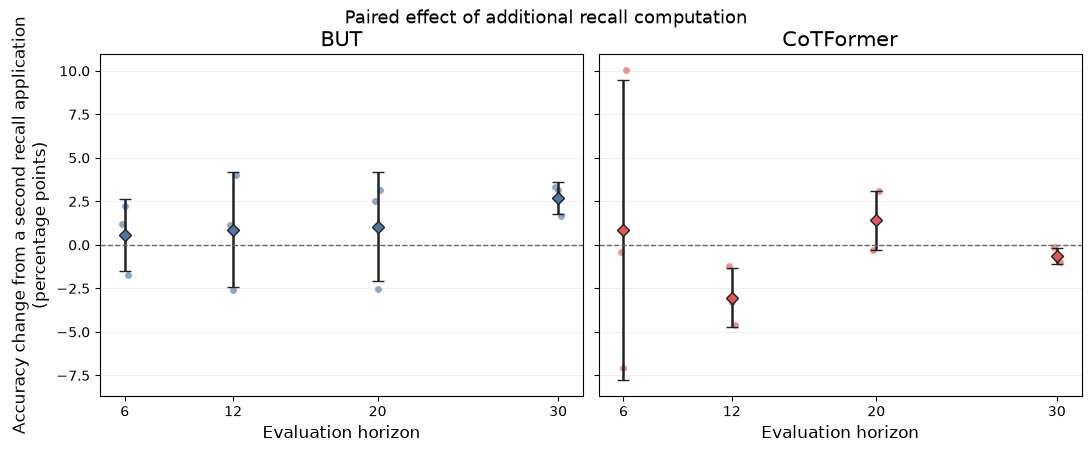

(PosixPath('/home/aras/dev/rs-cot/dis-draft/dis-images/delayed-recall/delayed-recall-repeat-effect.png'),
 PosixPath('/home/aras/dev/rs-cot/dis-draft/dis-images/delayed-recall/delayed-recall-repeat-effect.pdf'))

In [11]:
repeat_rows = []
comparison_stems = {"dca_but": "but", "dca_cotf_cache": "cotformer"}
for model, stem in comparison_stems.items():
    for horizon in DELAYED_HORIZONS:
        path = DELAYED_REPORT_ROOT / f"{stem}_recall1_vs_2_h{horizon}" / "recall_repeat_paired_values.csv"
        data = pd.read_csv(path)
        selected = data[
            data["scope"].eq("overall_nontrivial")
            & data["metric"].eq("cell_accuracy")
        ].copy()
        if len(selected) != 3:
            raise ValueError(f"Expected three paired model seeds: {path}")
        for row in selected.itertuples(index=False):
            repeat_rows.append({
                "Model": model,
                "Horizon": horizon,
                "Model seed": row.model_seed,
                "Accuracy change": 100 * row.delta_two_minus_one,
            })
repeat_effects = pd.DataFrame(repeat_rows)

fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.2), sharey=True, constrained_layout=True)
seed_offsets = np.linspace(-0.16, 0.16, 3)
for axis, model in zip(axes, MODEL_ORDER):
    panel = repeat_effects[repeat_effects["Model"].eq(model)]
    for horizon in DELAYED_HORIZONS:
        values = panel[panel["Horizon"].eq(horizon)].sort_values("Model seed")["Accuracy change"].to_numpy()
        axis.scatter(horizon + seed_offsets, values, s=28, alpha=0.65, color=MODEL_COLORS[model], edgecolor="white", linewidth=0.5)
        axis.errorbar(
            horizon, values.mean(), yerr=values.std(ddof=1),
            fmt="D", markersize=6, capsize=4, linewidth=1.8,
            color="#222222", markerfacecolor=MODEL_COLORS[model],
        )
    axis.axhline(0, color="#666666", linestyle="--", linewidth=1)
    axis.set(title=MODEL_LABELS[model], xlabel="Evaluation horizon", xticks=DELAYED_HORIZONS)
    axis.grid(axis="y", alpha=0.2, linewidth=0.7)
axes[0].set_ylabel("Accuracy change from a second recall application\n(percentage points)")
fig.suptitle("Paired effect of additional recall computation", y=1.04)
repeat_effect_paths = save_delayed_figure(fig, "delayed-recall-repeat-effect")
plt.show()
plt.close(fig)
repeat_effect_paths